---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 2"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 6. Джерела струму, струмові дзеркала, диференціальні каскади</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>2.4. Джерела струму на транзисторах. Струмові дзеркала: приклади реалізації, переваги та недоліки, призначення, розрахункові співвідношення</li>
  <li>2.5. Каскад з активним та динамічним навантаженням: приклади реалізації, переваги та недоліки, призначення, розрахункові співвідношення</li>
  <li>2.6. Транзисторні балансні (диференціальні) схеми включення: приклади реалізації, переваги, призначення, розрахункові співвідношення</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 6 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Джерела струму на транзисторах. Струмові дзеркала](#current-sources)
    * [🔬 Інтерактивно: вихідні характеристики струмових дзеркал (PySpice)](#mirror-interactive)
* [Каскад з активним (динамічним) навантаженням](#active-load)
    * [🔬 Інтерактивно: резистивне і активне навантаження (PySpice)](#active-load-interactive)
* [Балансні (диференціальні) каскади](#diff-amp)
    * [🔬 Інтерактивно: диференціальний каскад: передавальна характеристика і КПСС (PySpice)](#diff-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Джерела струму на транзисторах. Струмові дзеркала <a class="anchor" id="current-sources"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.4</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, чим відрізняється джерело струму від джерела напруги, і чому транзистор є «природним» джерелом струму
> - Розраховувати струм і вихідний опір джерела струму з емітерною стабілізацією
> - Порівнювати просте дзеркало, дзеркало Відлара, Вілсона і каскодне дзеркало

</div>

**Ідеальне джерело струму** підтримує незмінний струм при будь-якій напрузі на навантаженні: його вихідний опір $R_{вих} \to \infty$. Колекторна характеристика біполярного транзистора в активному режимі майже горизонтальна — струм колектора майже не залежить від $U_{ке}$, тому транзистор з фіксованим струмом бази (емітера) і є джерелом струму. Вихідний опір обмежує ефект Ерлі: $r_к = U_A/I_к$ ($U_A$ — напруга Ерлі, 50…200 В).

### Джерело струму з емітерною стабілізацією

База транзистора має фіксований потенціал $U_б$ (дільник, стабілітрон або діоди), у колі емітера — резистор $R_е$:
$$I_{вих} \approx \frac{U_б - U_{бе}}{R_е},\qquad R_{вих} \approx r_к\left(1 + \frac{\beta R_е}{R_е + h_{11е} + R_б}\right)\;(\text{до } \beta r_к).$$
Резистор $R_е$ створює послідовний НЗЗ за струмом, який збільшує вихідний опір (тема 2). Для температурної компенсації $U_{бе}$ у дільник вмикають діод.

### Струмове дзеркало (відбивач струму)

Два **ідентичні** транзистори з об'єднаними базами й емітерами: VT1 увімкнено діодом (колектор з'єднано з базою), через нього задається опорний струм $I_{оп}$; VT2 має ту саму $U_{бе}$, тож його колекторний струм «відбиває» опорний:
$$I_{оп} = \frac{E_ж - U_{бе}}{R_{оп}},\qquad I_{вих} = \frac{I_{оп}}{1 + 2/\beta}\approx I_{оп},\qquad R_{вих} = r_{к2} = \frac{U_A}{I_{вих}} .$$
Масштабуванням площ емітерів ($n$ транзисторів у паралель) отримують $I_{вих} = nI_{оп}$. Дзеркала можливі лише в інтегральному виконанні, де транзистори на одному кристалі мають однакові параметри і температуру.

**Удосконалені дзеркала:**
- **Дзеркало Відлара** — у коло емітера VT2 вмикають резистор $R_е$: $U_{бе1} - U_{бе2} = I_{вих}R_е$, звідки $\;I_{вих}R_е = \varphi_т\ln(I_{оп}/I_{вих})$. Дає малі струми (мікроампери) без мегаомних резисторів і має більший $R_{вих}$.
- **Дзеркало Вілсона** (три транзистори) — НЗЗ за струмом зменшує похибку від струмів баз до $2/\beta^2$ і збільшує вихідний опір до $\approx\beta r_к/2$.
- **Каскодне дзеркало** — над простим дзеркалом ставлять каскодний транзистор (тема 5): $R_{вих} \approx \beta r_к$, напруга на VT2 зафіксована (немає ефекту Ерлі).

| Дзеркало | Похибка струму | $R_{вих}$ | Мінімальна вихідна напруга |
|---|---|---|---|
| просте | $2/\beta$ | $r_к$ | $U_{кенас} \approx 0{,}2$ В |
| Відлара | $\sim 2/\beta$, $I_{вих} \ll I_{оп}$ | $r_к(1 + g_mR_е)$ | ≈0,2 В + $I_{вих}R_е$ |
| Вілсона | $2/\beta^2$ | $\beta r_к/2$ | $U_{бе} + U_{кенас} \approx 0{,}9$ В |
| каскодне | $2/\beta$ | $\beta r_к$ | $U_{бе} + U_{кенас}$ |

**Призначення:** задання режимів усіх каскадів мікросхем (одне опорне коло — багато дзеркал), «хвостові» джерела диференціальних каскадів, активні навантаження, генератори лінійно змінної напруги (заряд конденсатора стабільним струмом), живлення світлодіодів і датчиків.

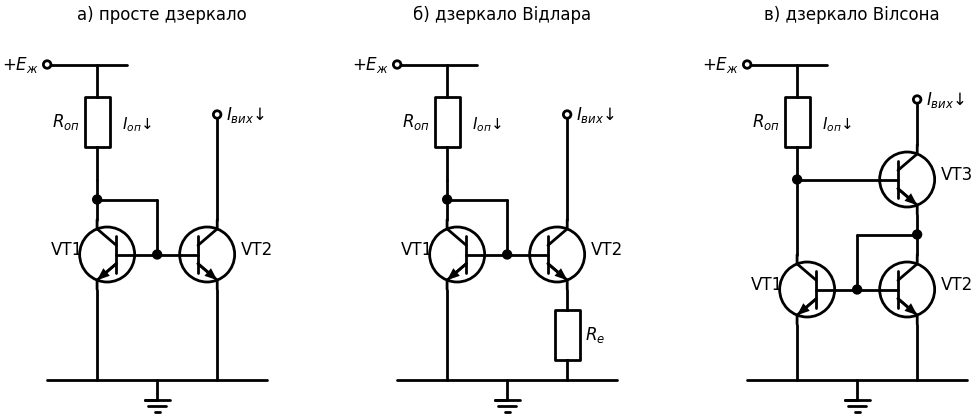

In [2]:
# а) просте дзеркало; б) дзеркало Відлара; в) дзеркало Вілсона
if SCHEMDRAW_AVAILABLE:
    def mirror(d, ox, kind, title):
        W = lambda p1, p2: elm.Line().at((ox + p1[0], p1[1])).to((ox + p2[0], p2[1]))
        d += elm.Label().at((ox + 2.2, 7.2)).label(title)
        d += W((0, 6.3), (1.6, 6.3)); d += elm.Dot(open=True).at((ox + 0, 6.3)).label('$+E_ж$', loc='left')
        d += elm.Resistor().at((ox + 1.0, 6.3)).to((ox + 1.0, 4.0)).label('$R_{оп}$', loc='top')
        d += W((0, 0), (4.4, 0)); d += elm.Ground().at((ox + 2.2, 0))
        d += elm.Label().at((ox + 1.7, 5.0)).label('$I_{оп}$↓', fontsize=11)
        if kind != 'wilson':
            d += elm.BjtNpn(circle=True).theta(0).reverse().at((ox + 1.75, 2.5)).anchor('base')     # VT1 (діодне ввімкнення)
            d += elm.BjtNpn(circle=True).theta(0).at((ox + 2.65, 2.5)).anchor('base')               # VT2
            d += elm.Label().at((ox + 0.3, 2.5)).label('VT1'); d += elm.Label().at((ox + 4.1, 2.5)).label('VT2')
            d += W((1.0, 4.0), (1.0, 3.2)); d += W((1.0, 3.6), (2.2, 3.6)); d += W((2.2, 3.6), (2.2, 2.5)); d += elm.Dot().at((ox + 1.0, 3.6))
            d += W((1.75, 2.5), (2.65, 2.5)); d += elm.Dot().at((ox + 2.2, 2.5))
            d += W((1.0, 1.8), (1.0, 0))
            if kind == 'widlar':
                d += elm.Resistor().at((ox + 3.4, 1.8)).to((ox + 3.4, 0)).label('$R_е$', loc='bottom')
            else:
                d += W((3.4, 1.8), (3.4, 0))
            d += W((3.4, 3.2), (3.4, 5.3)); d += elm.Dot(open=True).at((ox + 3.4, 5.3)).label('$I_{вих}$↓', loc='right')
        else:
            d += elm.BjtNpn(circle=True).theta(0).reverse().at((ox + 1.75, 1.8)).anchor('base')     # VT1
            d += elm.BjtNpn(circle=True).theta(0).at((ox + 2.65, 1.8)).anchor('base')               # VT2 (діодне)
            d += elm.BjtNpn(circle=True).theta(0).at((ox + 2.65, 4.0)).anchor('base')               # VT3 — вихідний
            d += elm.Label().at((ox + 0.3, 1.8)).label('VT1'); d += elm.Label().at((ox + 4.1, 1.8)).label('VT2'); d += elm.Label().at((ox + 4.1, 4.0)).label('VT3')
            d += W((1.0, 4.0), (1.0, 2.5)); d += elm.Dot().at((ox + 1.0, 4.0)); d += W((1.0, 4.0), (2.65, 4.0))
            d += W((1.75, 1.8), (2.65, 1.8)); d += elm.Dot().at((ox + 2.2, 1.8))
            d += W((2.2, 1.8), (2.2, 2.9)); d += W((2.2, 2.9), (3.4, 2.9)); d += elm.Dot().at((ox + 3.4, 2.9))
            d += W((3.4, 2.5), (3.4, 3.3)); d += W((1.0, 1.1), (1.0, 0)); d += W((3.4, 1.1), (3.4, 0))
            d += W((3.4, 4.7), (3.4, 5.6)); d += elm.Dot(open=True).at((ox + 3.4, 5.6)).label('$I_{вих}$↓', loc='right')
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        mirror(d, 0, 'simple', 'а) просте дзеркало')
        mirror(d, 7, 'widlar', 'б) дзеркало Відлара')
        mirror(d, 14, 'wilson', 'в) дзеркало Вілсона')

---
### 🔬 Інтерактивно: вихідні характеристики струмових дзеркал (PySpice) <a class="anchor" id="mirror-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Опорний струм задається резистором $R_{оп}$ від джерела 12 В. До виходу дзеркала під'єднано джерело напруги $U_{вих}$, яку розгортаємо від 0 до 12 В. Чим пологіша характеристика, тим більший вихідний опір. Змініть напругу Ерлі $U_A$ транзисторів: у простого дзеркала нахил визначається саме нею, а дзеркало Вілсона майже не реагує. Дзеркало Відлара з $R_е$ дає в кілька разів менший струм.

</div>

In [3]:
# Струмові дзеркала: I_вих(U_вих) для простого, Відлара і Вілсона (PySpice, модель NPN зі змінною U_A)
def mirrors(Rref_k=11.0, VA=60.0, Re=1000.0):
    def build(kind):
        c = Circuit(kind)
        c.model('QN', 'NPN', BF=150, IS=1e-14, VAF=VA)
        c.V('cc', 'vcc', c.gnd, 12); c.V('out', 'vo', c.gnd, 5)
        c.R('ref', 'vcc', 'r', Rref_k * 1e3)
        if kind == 'wilson':
            c.BJT(1, 'r', 'm', c.gnd, model='QN'); c.BJT(2, 'm', 'm', c.gnd, model='QN'); c.BJT(3, 'vo', 'r', 'm', model='QN')
        else:
            c.BJT(1, 'r', 'r', c.gnd, model='QN')
            if kind == 'widlar':
                c.BJT(2, 'vo', 'r', 'e2', model='QN'); c.R('e', 'e2', c.gnd, Re)
            else:
                c.BJT(2, 'vo', 'r', c.gnd, model='QN')
        return c
    fig, ax = plt.subplots(figsize=(9, 4.2))
    Iref = (12 - 0.65) / (Rref_k * 1e3)
    for kind, lab, col in (('simple', 'просте', '#2196F3'), ('widlar', f'Відлара (Rе = {Re:.0f} Ом)', '#FF9800'), ('wilson', 'Вілсона', '#4CAF50')):
        a = build(kind).simulator(temperature=25, nominal_temperature=25).dc(Vout=slice(0, 12, 0.05))
        u = np.array(a.sweep); i = -np.array(a.branches['vout']) * 1e3
        k1, k2 = np.argmin(abs(u - 4)), np.argmin(abs(u - 10))
        rout = (u[k2] - u[k1]) / ((i[k2] - i[k1]) * 1e-3)
        ax.plot(u, i, color=col, label=f'{lab}: I = {i[np.argmin(abs(u-6))]:.3f} мА, Rвих ≈ {rout/1e6:.2f} МОм')
    ax.axhline(Iref * 1e3, color='k', ls=':', lw=1, label=f'$I_{{оп}}$ ≈ {Iref*1e3:.3f} мА')
    ax.set_xlabel('$U_{вих}$, В'); ax.set_ylabel('$I_{вих}$, мА'); ax.set_ylim(0, Iref * 1e3 * 1.3); ax.legend(fontsize=9, loc='lower right')
    ax.set_title(f'Вихідні характеристики дзеркал ($U_A$ = {VA:.0f} В)')
    plt.tight_layout(); plt.show()

interact(mirrors,
         Rref_k=widgets.FloatSlider(min=2, max=50, step=1, value=11, description='Rоп (кОм)'),
         VA=widgets.FloatSlider(min=20, max=200, step=10, value=60, description='U_A (В)'),
         Re=widgets.FloatSlider(min=100, max=10000, step=100, value=1000, description='Rе (Ом)'));

interactive(children=(FloatSlider(value=11.0, description='Rоп (кОм)', max=50.0, min=2.0, step=1.0), FloatSlid…

---

## Каскад з активним (динамічним) навантаженням <a class="anchor" id="active-load"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.5</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати обмеження підсилення каскаду з резистивним навантаженням
> - Розраховувати коефіцієнт підсилення каскаду з активним навантаженням
> - Пояснювати, чому активне навантаження вимагає зворотного зв'язку за постійним струмом

</div>

Підсилення каскаду СЕ $K_u = -g_mR_к = -\dfrac{I_кR_к}{\varphi_т}$ пропорційне **падінню напруги** $I_кR_к$ на навантаженні. При живленні 12 В воно не може перевищити кількох вольт, тож $|K_u| \lesssim 200\ldots300$. Збільшити $R_к$ не можна, не зменшивши струм (а з ним і $g_m$).

**Активне (динамічне) навантаження** — замість $R_к$ вмикають джерело струму (транзистор протилежної провідності, найчастіше — вихід p-n-p дзеркала). Для **постійного** струму воно має малий опір (на ньому падає лише ~0,2…1 В), а для **змінного** — дуже великий (вихідний опір джерела струму $r_{к}$). Тоді
$$K_u = -g_m\,(r_{к1}\parallel r_{к2}\parallel R_н),\qquad\text{без навантаження}\quad K_u = -\frac{I_к}{\varphi_т}\cdot\frac{1}{2}\cdot\frac{U_A}{I_к} = -\frac{U_A}{2\varphi_т}.$$
При $U_A = 60$ В: $|K_u| \approx 1150$ — **на один каскад**, незалежно від струму! (Межа $g_mr_к = U_A/\varphi_т$ — «власне підсилення» транзистора.)

**Особливості і недоліки:**
- вихід каскаду — високоомний; будь-яке навантаження $R_н$ різко зменшує підсилення, тому після каскаду з активним навантаженням ставлять повторювач;
- робоча точка **не визначена**: два джерела струму (знизу — транзистор, зверху — дзеркало) «змагаються», і незначна різниця струмів виштовхує вихід у насичення одного з них. Потрібен **НЗЗ за постійним струмом** (загальний ЗЗ, як в ОП) або симетрична (диференціальна) структура;
- малий розмах вихідної напруги при насиченні одного з джерел; більший шум.

**Застосування:** практично всі каскади інтегральних ОП (вхідний диференціальний каскад з дзеркальним навантаженням, проміжний каскад СЕ з джерелом струму в колекторі), КМОН-підсилювачі, компаратори.

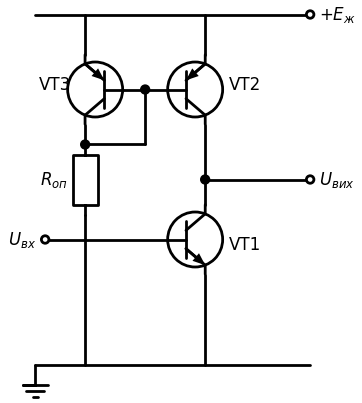

In [4]:
# Каскад СЕ з активним навантаженням: VT2–VT3 — p-n-p дзеркало, I_оп задає R_оп
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (5.5, 7)); d += elm.Dot(open=True).at((5.5, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (5.5, 0)); d += elm.Ground().at((0, 0))
        d += elm.BjtPnp(circle=True).theta(0).reverse().at((1.75, 5.5)).anchor('base'); d += elm.Label().at((0.3, 5.5)).label('VT3')
        d += elm.BjtPnp(circle=True).theta(0).at((2.65, 5.5)).anchor('base'); d += elm.Label().at((4.1, 5.5)).label('VT2')
        d += W((1.0, 6.2), (1.0, 7)); d += W((3.4, 6.2), (3.4, 7)); d += W((1.75, 5.5), (2.65, 5.5)); d += elm.Dot().at((2.2, 5.5))
        d += W((1.0, 4.8), (1.0, 4.4)); d += W((1.0, 4.4), (2.2, 4.4)); d += W((2.2, 4.4), (2.2, 5.5)); d += elm.Dot().at((1.0, 4.4))
        d += elm.Resistor().at((1.0, 4.4)).to((1.0, 3.0)).label('$R_{оп}$', loc='top'); d += W((1.0, 3.0), (1.0, 0))
        d += W((3.4, 4.8), (3.4, 3.2)); d += elm.Dot().at((3.4, 3.7)); d += W((3.4, 3.7), (5.5, 3.7)); d += elm.Dot(open=True).at((5.5, 3.7)).label('$U_{вих}$', loc='right')
        d += elm.BjtNpn(circle=True).theta(0).at((2.65, 2.5)).anchor('base'); d += elm.Label().at((4.1, 2.3)).label('VT1')
        d += elm.Dot(open=True).at((0.2, 2.5)).label('$U_{вх}$', loc='left'); d += W((0.2, 2.5), (2.65, 2.5))
        d += W((3.4, 1.8), (3.4, 0))

---
### 🔬 Інтерактивно: резистивне і активне навантаження (PySpice) <a class="anchor" id="active-load-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад СЕ на n-p-n транзисторі з однаковим струмом спокою ≈1 мА: (1) навантаження — резистор $R_к = 6$ кОм; (2) навантаження — p-n-p дзеркало. Для активного навантаження потрібне точне зміщення, тому вхід керується від ОП через НЗЗ за постійним струмом (інтегрувальне коло, не показане) — тут ми просто підбираємо вхідну напругу так, щоб вихід був посередині. Порівняйте коефіцієнти підсилення і вплив навантаження $R_н$.

</div>

In [5]:
# Каскад СЕ: резистор R_к проти активного навантаження (p-n-p дзеркало); AC з точним DC-зміщенням
def active_load(Rl_k=1000.0, VA=60.0):
    def build(kind, vb):
        c = Circuit(kind)
        c.model('QN', 'NPN', BF=150, IS=1e-14, VAF=VA); c.model('QP', 'PNP', BF=100, IS=1e-14, VAF=VA)
        c.V('cc', 'vcc', c.gnd, 12)
        c.SinusoidalVoltageSource('in', 'b', c.gnd, dc_offset=vb, offset=vb, amplitude=1e-4, ac_magnitude=1)
        c.BJT(1, 'out', 'b', c.gnd, model='QN')
        if kind == 'res':
            c.R('c', 'vcc', 'out', 6e3)
        else:
            c.R('ref', 'r', c.gnd, 11.3e3); c.BJT(3, 'r', 'r', 'vcc', model='QP'); c.BJT(2, 'out', 'r', 'vcc', model='QP')
        c.R('L', 'out', c.gnd, Rl_k * 1e3)
        return c
    def find_bias(kind):
        lo, hi = 0.5, 0.8                     # бісекція: напруга бази, за якої U_вих = 6 В
        for _ in range(60):
            m = (lo + hi) / 2
            op = build(kind, m).simulator(temperature=25, nominal_temperature=25).operating_point()
            if float(np.array(op['out'])[0]) > 6: lo = m
            else: hi = m
        return m
    fig, ax = plt.subplots(figsize=(9, 4))
    out = []
    for kind, lab, col in (('res', 'резистор Rк = 6 кОм', '#2196F3'), ('act', 'активне навантаження', '#F44336')):
        vb = find_bias(kind)
        f, v = ac(build(kind, vb), 10, 1e8, 20); g = np.abs(v['out'])
        ax.semilogx(f, db(g), color=col, label=f'{lab}: |K| = {g[0]:.0f}'); out.append(g[0])
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('K, дБ'); ax.legend(); ax.set_ylim(0, 75)
    ax.set_title(f'$R_н$ = {Rl_k:g} кОм,  $U_A$ = {VA:.0f} В  (модель без ємностей — АЧХ пласка)')
    plt.tight_layout(); plt.show()
    print(f'Межа «власного підсилення» U_A/(2φт) = {VA/(2*0.02585):.0f};  оцінка −g_m·R_к = {1e-3/0.02585*6e3:.0f}')

interact(active_load,
         Rl_k=widgets.FloatLogSlider(base=10, min=0, max=4, step=0.1, value=1000, description='Rн (кОм)'),
         VA=widgets.FloatSlider(min=20, max=200, step=10, value=60, description='U_A (В)'));

interactive(children=(FloatLogSlider(value=1000.0, description='Rн (кОм)'), FloatSlider(value=60.0, descriptio…

---

## Балансні (диференціальні) каскади <a class="anchor" id="diff-amp"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.6</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип дії диференціального каскаду і поняття диференціального та синфазного сигналів
> - Розраховувати коефіцієнти підсилення диференціального і синфазного сигналів, КПСС
> - Пояснювати переваги «хвостового» джерела струму і дзеркального навантаження

</div>

**Диференціальний (балансний) каскад** — два ідентичні транзистори VT1, VT2 зі спільним емітерним колом (резистор $R_е$ або джерело струму $I_0$) і однаковими колекторними навантаженнями $R_к$. Схема симетрична, як міст: зміни температури і живлення однаково діють на обидва плечі й **компенсуються** на диференціальному виході $U_{вих} = U_{к1} - U_{к2}$. Тому диференціальні каскади — основа підсилювачів постійного струму з малим дрейфом нуля і вхідних каскадів усіх ОП.

**Вхідні сигнали** розкладають на складові:
$$U_д = U_{вх1} - U_{вх2}\;(\text{диференціальний}),\qquad U_{сф} = \frac{U_{вх1} + U_{вх2}}{2}\;(\text{синфазний}).$$

### Диференціальний сигнал

Струм $I_0 = 2I_{е0}$ ділиться між транзисторами; потенціал емітерів для малого диференціального сигналу не змінюється (віртуальна земля). Кожне плече працює як каскад СЕ:
$$K_д = \frac{U_{вих}}{U_д} = g_mR_к\;(\text{диференціальний вихід}),\qquad K_{д1} = \frac{g_mR_к}{2}\;(\text{несиметричний вихід}),\qquad R_{вх.д} = 2h_{11е}.$$
Великий сигнал: $\;I_{к1,2} = \dfrac{I_0}{2}\left(1 \pm \tanh\dfrac{U_д}{2\varphi_т}\right)$ — лінійна ділянка лише ±(20…30) мВ, далі весь струм перемикається в одне плече (обмеження).

### Синфазний сигнал

Обидва струми змінюються однаково; спільне коло емітерів створює глибокий НЗЗ ($R_е$ «бачать» обидва плечі — для кожного це $2R_е$):
$$K_{сф1} = \frac{U_{к1}}{U_{сф}} \approx -\frac{R_к}{2R_е},\qquad K_{сф} = 0\;(\text{диференціальний вихід, ідеальна симетрія}).$$

**Коефіцієнт послаблення синфазного сигналу (КПСС, CMRR):**
$$\text{КПСС} = \frac{K_д}{K_{сф}},\qquad \text{КПСС}_1 \approx \frac{g_mR_к/2}{R_к/2R_е} = g_mR_е\;(\text{несиметричний вихід}).$$
Для великого КПСС потрібен якомога більший опір у колі емітерів — тому замість $R_е$ вмикають **джерело струму** («хвіст» з $R_{вих} \sim$ МОм): КПСС зростає до 80…120 дБ.

**Дзеркальне навантаження.** Якщо замість двох $R_к$ увімкнути p-n-p дзеркало (VT1 — у діодне плече), струм VT1 «відбивається» у вихідне плече, і на несиметричному виході підсумовуються зміни обох струмів: підсилення як у диференціального виходу ($g_m r_к/2$), без втрати половини сигналу. Саме так побудовано вхідний каскад більшості ОП.

**Інші параметри:** напруга зміщення нуля $U_{зм}$ (від розбалансу $U_{бе}$ — одиниці мВ, у прецизійних схемах — мкВ), різниця і середній вхідний струм, температурний дрейф $dU_{зм}/dT$ (≈ 3…5 мкВ/°C на 1 мВ $U_{зм}$).

**Застосування:** вхідні каскади ОП і компараторів, вимірювальні підсилювачі, підсилювачі сигналів з кабельних ліній з синфазною завадою (RS-485, CAN, LVDS-приймачі), аналогові перемножувачі (комірка Гілберта), балансні модулятори і змішувачі, обмежувачі.

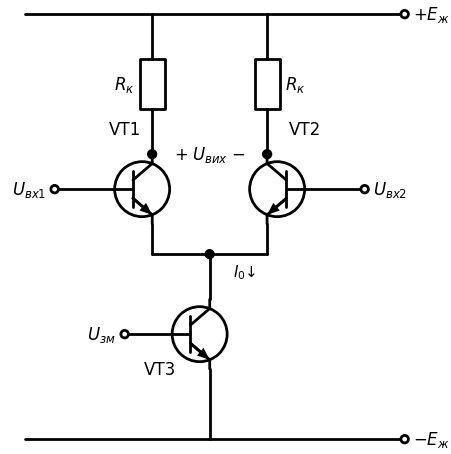

In [6]:
# Диференціальний каскад з «хвостовим» джерелом струму на VT3
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (7.6, 7)); d += elm.Dot(open=True).at((7.6, 7)).label('$+E_ж$', loc='right')
        d += W((0, -1.5), (7.6, -1.5)); d += elm.Dot(open=True).at((7.6, -1.5)).label('$-E_ж$', loc='right')
        d += elm.BjtNpn(circle=True).theta(0).at((1.8, 3.5)).anchor('base'); d += elm.Label().at((1.9, 4.6)).label('VT1')
        d += elm.BjtNpn(circle=True).theta(0).reverse().at((5.6, 3.5)).anchor('base'); d += elm.Label().at((5.5, 4.6)).label('VT2')
        d += elm.Dot(open=True).at((0.6, 3.5)).label('$U_{вх1}$', loc='left'); d += W((0.6, 3.5), (1.8, 3.5))
        d += elm.Dot(open=True).at((6.8, 3.5)).label('$U_{вх2}$', loc='right'); d += W((5.6, 3.5), (6.8, 3.5))
        d += elm.Resistor().at((2.55, 7)).to((2.55, 4.2)).label('$R_к$', loc='top'); d += elm.Resistor().at((4.85, 7)).to((4.85, 4.2)).label('$R_к$', loc='bottom')
        d += elm.Dot().at((2.55, 4.2)); d += elm.Dot().at((4.85, 4.2))
        d += elm.Gap().at((2.55, 4.2)).to((4.85, 4.2)).label(['+', '$U_{вих}$', '−'], loc='bottom')
        d += W((2.55, 2.8), (2.55, 2.2)); d += W((4.85, 2.8), (4.85, 2.2)); d += W((2.55, 2.2), (4.85, 2.2)); d += elm.Dot().at((3.7, 2.2))
        d += elm.Label().at((4.3, 1.75)).label('$I_0$↓', fontsize=11)
        d += elm.BjtNpn(circle=True).theta(0).at((2.95, 0.6)).anchor('base'); d += elm.Label().at((2.6, -0.2)).label('VT3')
        d += W((3.7, 2.2), (3.7, 1.3)); d += W((3.7, -0.1), (3.7, -1.5))
        d += W((2.95, 0.6), (2.0, 0.6)); d += elm.Dot(open=True).at((2.0, 0.6)).label('$U_{зм}$', loc='left')

---
### 🔬 Інтерактивно: диференціальний каскад: передавальна характеристика і КПСС (PySpice) <a class="anchor" id="diff-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад на 2N3904 ($\pm12$ В, $R_к = 10$ кОм, струм «хвоста» 1 мА) з резистором $R_е$ або джерелом струму (дзеркалом) у спільному колі емітерів. Ліворуч — струми колекторів від диференціальної напруги (функція $\tanh$); праворуч — несиметричний вихід при диференціальному і синфазному сигналах, звідки обчислюється КПСС.

</div>

In [7]:
# Диференціальний каскад: DC-передавальна характеристика, K_д, K_сф, КПСС
def diff_amp(tail='джерело струму', Ud_mV=10.0):
    def build(mode, vd=0.0):
        c = Circuit('diff pair')
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12); c.V('ee', 'vee', c.gnd, -12)
        if mode == 'dc':
            c.V('d', 'b1', 'b2', vd); c.V('c', 'b2', c.gnd, 0)
        elif mode == 'diff':
            c.SinusoidalVoltageSource('d1', 'b1', c.gnd, amplitude=1e-3, ac_magnitude=0.5)
            c.SinusoidalVoltageSource('d2', 'b2', c.gnd, amplitude=1e-3, ac_magnitude=-0.5)
        else:
            c.SinusoidalVoltageSource('c1', 'b1', c.gnd, amplitude=1e-3, ac_magnitude=1)
            c.SinusoidalVoltageSource('c2', 'b2', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.BJT(1, 'c1', 'b1', 'e', model='Q2N3904'); c.BJT(2, 'c2', 'b2', 'e', model='Q2N3904')
        c.R('c1', 'vcc', 'c1', 10e3); c.R('c2', 'vcc', 'c2', 10e3)
        if tail == 'резистор Rе':
            c.R('e', 'e', 'vee', 11.3e3)
        else:                                   # дзеркало: I_оп ≈ 1 мА
            c.R('ref', c.gnd, 'r', 11.3e3)
            c.BJT(4, 'r', 'r', 'vee', model='Q2N3904'); c.BJT(3, 'e', 'r', 'vee', model='Q2N3904')
        return c
    a = build('dc').simulator(temperature=25, nominal_temperature=25).dc(Vd=slice(-0.15, 0.15, 0.001))
    ud = np.array(a.sweep); i1 = (12 - np.array(a['c1'])) / 10e3 * 1e3; i2 = (12 - np.array(a['c2'])) / 10e3 * 1e3
    def ac1(c):                                   # AC-аналіз в одній точці (100 Гц)
        a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=100, stop_frequency=100, number_of_points=1, variation='lin')
        return {k: np.array(a[k]) for k in ('c1', 'c2')}
    vd_, vc_ = ac1(build('diff')), ac1(build('cm'))
    Kd = abs(vd_['c2'][0]); Kc = abs(vc_['c2'][0]); Kdd = abs(vd_['c1'][0] - vd_['c2'][0]); Kcd = abs(vc_['c1'][0] - vc_['c2'][0])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.plot(ud * 1e3, i1, color='#2196F3', label='$I_{к1}$'); a1.plot(ud * 1e3, i2, color='#F44336', label='$I_{к2}$')
    I0 = i1[len(i1)//2] + i2[len(i2)//2]
    a1.plot(ud * 1e3, I0 / 2 * (1 + np.tanh(ud / 2 / 0.02585)), 'k:', lw=1, label='$\\frac{I_0}{2}(1+\\tanh\\frac{U_д}{2\\varphi_т})$')
    a1.set_xlabel('$U_д$, мВ'); a1.set_ylabel('мА'); a1.legend(fontsize=9); a1.set_title('Перерозподіл струму «хвоста»')
    t = np.linspace(0, 2e-3, 400)
    a2.plot(t * 1e3, Kd * Ud_mV * np.sin(2 * np.pi * 1e3 * t), color='#2196F3', label=f'від $U_д$ = {Ud_mV:.0f} мВ (K = {Kd:.0f})')
    a2.plot(t * 1e3, Kc * 1000 * np.sin(2 * np.pi * 1e3 * t), color='#FF9800', label=f'від $U_{{сф}}$ = 1 В (K = {Kc:.4f})')
    a2.set_xlabel('t, мс'); a2.set_ylabel('$u_{к2}$, мВ'); a2.legend(fontsize=9); a2.set_title(f'Несиметричний вихід: КПСС = {20*np.log10(Kd/Kc):.0f} дБ')
    plt.tight_layout(); plt.show()
    print(f'Хвіст: {tail};  I0 = {I0:.3f} мА;  K_д1 = {Kd:.1f} (оцінка g_m·R_к/2 = {I0/2/25.85*10e3/2:.1f});  K_сф1 = {Kc:.2e};  '
          f'КПСС₁ = {20*np.log10(Kd/Kc):.1f} дБ;  диференціальний вихід: K_д = {Kdd:.1f}, K_сф = {Kcd:.1e}')

interact(diff_amp,
         tail=widgets.ToggleButtons(options=['резистор Rе', 'джерело струму'], value='джерело струму', description='Хвіст'),
         Ud_mV=widgets.FloatSlider(min=1, max=20, step=1, value=10, description='Uд (мВ)'));

interactive(children=(ToggleButtons(description='Хвіст', index=1, options=('резистор Rе', 'джерело струму'), v…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Диференціальний каскад лінійний лише в межах ±(1…2)$\varphi_т$.** При $|U_д| > 50…100$ мВ весь струм «хвоста» перемикається в одне плече — каскад обмежує сигнал. Тому в ОП диференціальний каскад завжди охоплено глибоким НЗЗ, який утримує $U_д \approx 0$ (принцип «віртуального короткого замикання», тема 7). Для розширення лінійної ділянки в емітери вмикають невеликі резистори (емітерна дегенерація) — ціною зменшення $g_m$.

</div>

---
### ⚡ Практичне застосування: джерела струму і диференціальні каскади

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Пристрій | Використання |
|---|---|
| ОП μA741 | вхідна пара СК–СБ з дзеркальним навантаженням, дзеркала Відлара для мікроамперних струмів, активне навантаження проміжного каскаду |
| Компаратори (LM311, LM393) | диференціальний вхід, дзеркальне навантаження |
| Приймачі RS-485 / CAN / LVDS | диференціальні каскади з великим КПСС для придушення синфазних завад кабелю |
| Комірка Гілберта (MC1496, AD633) | перемножувач/змішувач на трьох диференціальних парах |
| Драйвери світлодіодів, датчиків | джерела стабільного струму |
| Генератори пилкоподібної напруги | заряд конденсатора від джерела струму |

</div>

---
### ✅ Питання для самоперевірки: джерела струму, дзеркала, диференціальні каскади

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому струмове дзеркало можна виготовити лише в інтегральному виконанні?</summary>

> **Відповідь:** Воно вимагає однакових $I_S$ і температури обох транзисторів: на одному кристалі вони виготовлені в одному процесі поруч, а дискретні транзистори мають розкид $U_{бе}$ на десятки мВ.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як дзеркало Вілсона зменшує похибку?</summary>

> **Відповідь:** Вихідний транзистор VT3 охоплено НЗЗ через VT1–VT2: похибка від струмів баз зменшується з $2/\beta$ до $2/\beta^2$, вихідний опір зростає до $\beta r_к/2$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому каскад з активним навантаженням має підсилення ~1000?</summary>

> **Відповідь:** $K_u = g_m(r_{к1}\parallel r_{к2}) = U_A/(2\varphi_т)$ — визначається напругою Ерлі, а не напругою живлення.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Що таке КПСС і як його збільшити?</summary>

> **Відповідь:** Відношення коефіцієнтів підсилення диференціального і синфазного сигналів. Збільшують джерелом струму в колі емітерів (великий опір), симетрією плечей, диференціальним виходом.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому диференціальний каскад має малий дрейф нуля?</summary>

> **Відповідь:** Температурні зміни $U_{бе}$ і $\beta$ однакові в обох плечах — це синфазна зміна, яка компенсується на диференціальному виході.

</details>

---
### 📝 Задачі для самостійного розв'язання: джерела струму і диференціальні каскади


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Просте дзеркало: $E_ж = 15$ В, $R_{оп} = 14{,}3$ кОм, $\beta = 100$, $U_A = 80$ В. Знайдіть $I_{вих}$ і $R_{вих}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $I_{оп} = (15 - 0{,}7)/14{,}3 = 1$ мА; $I_{вих} = 1/(1 + 0{,}02) = 0{,}98$ мА; $R_{вих} = 80/0{,}98 \approx 82$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Дзеркало Відлара: $I_{оп} = 1$ мА, потрібно $I_{вих} = 10$ мкА. Знайдіть $R_е$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R_е = \dfrac{\varphi_т}{I_{вих}}\ln\dfrac{I_{оп}}{I_{вих}} = \dfrac{0{,}026}{10^{-5}}\ln100 \approx 12$ кОм (для простого дзеркала знадобився б $R_{оп} \approx 1{,}4$ МОм).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Диференціальний каскад: $I_0 = 2$ мА, $R_к = 5$ кОм, $R_е = 10$ кОм. Знайдіть $K_{д1}$, $K_{сф1}$ і КПСС (несиметричний вихід).

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $g_m = 1/26$ А/В·1 мА = 38,5 мА/В; $K_{д1} = g_mR_к/2 = 96$; $K_{сф1} = R_к/(2R_е) = 0{,}25$; КПСС $= 385$ (51,7 дБ).

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Основні співвідношення |
|---|---|
| Джерело струму з $R_е$ | $I \approx (U_б - U_{бе})/R_е$, $R_{вих} \lesssim\beta r_к$ |
| Просте дзеркало | $I_{вих} = I_{оп}/(1 + 2/\beta)$, $R_{вих} = r_к = U_A/I$ |
| Дзеркало Відлара | $I_{вих}R_е = \varphi_т\ln(I_{оп}/I_{вих})$ |
| Дзеркало Вілсона / каскодне | похибка $2/\beta^2$ / $2/\beta$; $R_{вих} \sim\beta r_к$ |
| Активне навантаження | $K_u = g_m(r_{к1}\parallel r_{к2}) \approx U_A/2\varphi_т$ |
| Диференціальний каскад | $K_д = g_mR_к$, $K_{д1} = g_mR_к/2$, $K_{сф1} \approx R_к/2R_е$, КПСС$_1 \approx g_mR_е$ |

**Головні висновки.** Джерела струму і дзеркала задають режими і служать високоомними навантаженнями в інтегральних схемах; активне навантаження дає підсилення ~1000 на каскад. Диференціальний каскад розрізняє корисний (диференціальний) і завадовий (синфазний) сигнали та компенсує дрейф — тому він є вхідним каскадом кожного операційного підсилювача.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Gray P. R., Hurst P. J., Lewis S. H., Meyer R. G. Analysis and Design of Analog Integrated Circuits. — 5th ed. — Wiley, 2009.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 5. Складові повторювачі, підсилювальні двійки, каскодні схеми](Тема_05_Складові_повторювачі_двійки_каскод.ipynb) &nbsp;|&nbsp; [Тема 7. Операційні підсилювачі. Основні схеми включення](Тема_07_Операційні_підсилювачі_основні_схеми.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*